# CNN from Scratch: Tea Leaf Disease Classification

**Dataset:** [Tea leaf disease Dataset](https://data.mendeley.com/datasets/mz598gxfw9/1), Mendeley Data, Version 1 (14 April 2025), DOI: 10.17632/mz598gxfw9.1 (Md Samiul Islam)  
**Task:** 6-class image classification: *Algal Leaf Spot, Brown Blight, Gray Blight, Helopeltis, Red Leaf Spot, Healthy*. The dataset has 5,180 images of detached tea leaves, photographed under varied lighting and backgrounds and annotated with bounding boxes on Roboflow. We convert the box labels into one label per image.  
**Framework:** PyTorch, a basic CNN built and trained from scratch (no pretrained weights)  
**Runs on:** Google Colab free tier (turn on the GPU: *Runtime → Change runtime type → T4 GPU*)

### What this notebook does
1. Loads the dataset (from Google Drive or a direct upload) and explores it.
2. Converts the Roboflow bounding-box labels into one label per image, removes augmented copies and photos repeated across splits, and uses the dataset's own **train / validation / test** split (2,278 / 364 / 369 images).
3. **Round 1:** trains a *basic CNN* (no augmentation, no dropout, no BatchNorm) and shows overfitting.
4. Visualizes the learned **filters** and **feature maps**.
5. **Round 2:** trains an *improved CNN* (data augmentation, BatchNorm, dropout, LR scheduler).
6. **Result analysis:** learning curves, test accuracy, confusion matrix, precision/recall/F1, per-class accuracy, ROC curves, misclassified images, sample predictions, and a comparison of the two rounds.

> Run every cell from top to bottom (`Runtime → Run all`). The only manual step is the dataset upload in **Section 2**.

## 1. Setup

Import the libraries, fix the random seeds so results are repeatable, and pick the device (GPU if available).

In [1]:
# Core PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Data, metrics, plotting
import os, glob, zipfile, shutil, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             accuracy_score, precision_recall_fscore_support, roc_curve, auc)
from sklearn.preprocessing import label_binarize

# Reproducibility
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if device.type == "cpu":
    print("⚠️  No GPU found. In Colab: Runtime → Change runtime type → T4 GPU, then run again.")

# Folder where every figure / table / model is saved
RESULTS_DIR = "/content/results" if os.path.exists("/content") else "results"
os.makedirs(RESULTS_DIR, exist_ok=True)

Using device: cuda


## 2. Get the dataset

This dataset was exported from **Roboflow** in YOLO object-detection format. Its layout is not one folder per class:

```
Tea Leaf Diseases/
├── data.yaml            ← the list of class names
├── train/  images/ + labels/
├── valid/  images/ + labels/
└── test/   images/ + labels/
```

Each image has a `.txt` label file with one line per **bounding box**: `class_id x_center y_center width height`. Section 2b turns these box labels into one class label per image.

**Where the notebook looks for the data (in this order):**
1. `My Drive/Tea leaf disease Dataset/Tea Leaf Diseases`, the folder you uploaded. It also searches up to 4 folder levels deep in My Drive for any folder holding `data.yaml` plus `train/`.
2. Any zip in My Drive whose name contains "Tea" or "tea" (e.g. the original Mendeley download).
3. Otherwise it shows an **upload button**, where you can choose the zip from your computer.

Click **Allow** when Colab asks for access to Google Drive. The data is then **copied to Colab's local disk** (`/content/tea_data`), because reading thousands of small files directly from Drive is very slow. The copy can take a few minutes. If it takes more than ~10 minutes, upload the Mendeley zip to My Drive instead (option 2 is much faster).

In [2]:
LOCAL_DIR = "/content/tea_data" if os.path.exists("/content") else "tea_data"
IMG_EXT   = (".jpg", ".jpeg", ".png", ".bmp")
MY_DRIVE  = "/content/drive/MyDrive"

def find_yolo_root(base):
    # Return the first folder under `base` that holds data.yaml and a train/ folder
    for cur, dirs, files in os.walk(base):
        dirs[:] = [d for d in dirs if d != "__MACOSX" and not d.startswith(".")]
        if "data.yaml" in files and "train" in dirs:
            return cur
    return None

def extract_all(zip_path, out_dir):
    print("Extracting", zip_path, "...")
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(out_dir)
    for _ in range(3):                                   # zips inside the zip
        inner = glob.glob(os.path.join(out_dir, "**", "*.zip"), recursive=True)
        if not inner:
            break
        for p in inner:
            with zipfile.ZipFile(p) as z:
                z.extractall(os.path.splitext(p)[0])
            os.remove(p)

DATA_ROOT = find_yolo_root(LOCAL_DIR) if os.path.exists(LOCAL_DIR) else None
if DATA_ROOT:
    print("Dataset already on local disk:", DATA_ROOT)
else:
    try:
        from google.colab import drive
        if not os.path.exists(MY_DRIVE):
            drive.mount("/content/drive")
    except Exception as e:
        print("Google Drive not used:", e)

    # 1) the unzipped folder on Drive
    src = None
    if os.path.exists(MY_DRIVE):
        candidates = [os.path.join(MY_DRIVE, "Tea leaf disease Dataset", "Tea Leaf Diseases")]
        for depth in range(0, 4):
            candidates += [os.path.dirname(p) for p in
                           glob.glob(os.path.join(MY_DRIVE, *(["*"] * depth), "data.yaml"))]
        candidates = [c for c in dict.fromkeys(candidates)
                      if os.path.exists(os.path.join(c, "data.yaml")) and os.path.isdir(os.path.join(c, "train"))]
        candidates.sort(key=lambda c: "tea" not in c.lower())      # prefer folders with "tea" in the path
        if candidates:
            src = candidates[0]
    if src:
        print("Found dataset folder on Drive:", src)
        print("Copying to local disk (can take a few minutes)...")
        t0 = time.time()
        shutil.copytree(src, os.path.join(LOCAL_DIR, os.path.basename(src)), dirs_exist_ok=True)
        print(f"Copied in {time.time()-t0:.0f}s")
    else:
        # 2) a zip on Drive, 3) a direct upload
        hits = []
        if os.path.exists(MY_DRIVE):
            for depth in range(0, 4):
                hits += glob.glob(os.path.join(MY_DRIVE, *(["*"] * depth), "*[Tt]ea*.zip"))
        if hits:
            extract_all(hits[0], LOCAL_DIR)
        else:
            from google.colab import files
            print("Dataset not found on Drive. Please upload the dataset zip ...")
            up = files.upload()
            extract_all(os.path.abspath(list(up.keys())[0]), LOCAL_DIR)
    DATA_ROOT = find_yolo_root(LOCAL_DIR)

if DATA_ROOT is None:
    raise RuntimeError("Could not find a folder with data.yaml and train/. Check the Drive folder or zip.")
print("✅ Dataset root:", DATA_ROOT)
print("Contents:", sorted(os.listdir(DATA_ROOT)))

Mounted at /content/drive
Found dataset folder on Drive: /content/drive/MyDrive/Tea leaf disease Dataset/Tea Leaf Diseases
Copying to local disk (can take a few minutes)...
Copied in 196s
✅ Dataset root: /content/tea_data/Tea Leaf Diseases
Contents: ['README.dataset.txt', 'README.roboflow.txt', 'data.yaml', 'test', 'train', 'valid']


### 2b. Turn the bounding-box labels into one class per image

We are doing **image classification**, so each image needs **one** label. For every image we read its label file and add up the **box area per class**. The image gets the class that covers the most area. Then:

- **Images with no boxes** are dropped (their class is unknown).
- **Mixed images**, where the main class covers less than 60% of the labelled area, are dropped: their label would be ambiguous. Images whose boxes mostly belong to one class are kept with that class.
- **Roboflow augmented copies.** Roboflow can export several augmented versions of the same photo, named `photo_jpg.rf.<random>.jpg`. We keep **one image per original photo**, so Round 1 really trains without augmentation, and no copies of one photo can sit in two splits.
- **Leakage check.** A photo that appears in more than one split (same original name, or a byte-identical file) is kept only in the training set. Byte-identical files with **different labels** are removed.

Every count is printed, so you can see exactly what was kept.

In [3]:
import yaml
with open(os.path.join(DATA_ROOT, "data.yaml")) as f:
    cfg = yaml.safe_load(f)
names = cfg["names"]
class_names = [str(names[k]) for k in sorted(names)] if isinstance(names, dict) else [str(n) for n in names]
NUM_CLASSES = len(class_names)
print(f"{NUM_CLASSES} classes from data.yaml:", class_names)

MIN_SHARE = 0.60          # the main class must cover at least 60% of the labelled box area
SPLIT_DIRS = {"train": "train", "valid": "val", "val": "val", "test": "test"}

def label_file(img_path):
    d, fn = os.path.split(img_path)
    stem = os.path.splitext(fn)[0]
    cands = []
    if os.path.basename(d) == "images":
        cands.append(os.path.join(os.path.dirname(d), "labels", stem + ".txt"))
    cands.append(os.path.join(d, stem + ".txt"))
    return next((c for c in cands if os.path.exists(c)), None)

def class_areas(path):
    areas = {}
    with open(path) as f:
        for line in f:
            parts = line.split()
            if len(parts) < 5:
                continue
            c = int(float(parts[0])); v = [float(x) for x in parts[1:]]
            if len(v) == 4:                       # YOLO box: x_center y_center width height
                w, h = v[2], v[3]
            else:                                 # polygon: x1 y1 x2 y2 ...
                xs, ys = v[0::2], v[1::2]
                w, h = max(xs) - min(xs), max(ys) - min(ys)
            areas[c] = areas.get(c, 0.0) + max(w * h, 1e-6)
    return areas

def original_name(fn):
    stem = os.path.splitext(fn)[0]
    return stem.split(".rf.")[0] if ".rf." in stem else stem

stats = {k: 0 for k in ["images", "no_label", "bad_class", "mixed_kept", "ambiguous_dropped", "aug_copies_removed"]}
records = []
for folder, split in SPLIT_DIRS.items():
    sdir = os.path.join(DATA_ROOT, folder)
    if not os.path.isdir(sdir):
        continue
    imgs = sorted(p for p in glob.glob(os.path.join(sdir, "**", "*"), recursive=True)
                  if p.lower().endswith(IMG_EXT) and not os.path.basename(p).startswith("."))
    seen_orig = set()
    for p in imgs:
        stats["images"] += 1
        lf = label_file(p)
        areas = class_areas(lf) if lf else {}
        if not areas:
            stats["no_label"] += 1; continue
        if any(c < 0 or c >= NUM_CLASSES for c in areas):
            stats["bad_class"] += 1; continue
        main = max(areas, key=areas.get)
        share = areas[main] / sum(areas.values())
        if share < MIN_SHARE:
            stats["ambiguous_dropped"] += 1; continue
        if len(areas) > 1:
            stats["mixed_kept"] += 1
        orig = original_name(os.path.basename(p))
        if orig in seen_orig:
            stats["aug_copies_removed"] += 1; continue
        seen_orig.add(orig)
        records.append({"path": p, "label": main, "split": split, "orig": orig})

print("\nImages found               :", stats["images"])
print("No boxes (dropped)         :", stats["no_label"])
print("Unknown class id (dropped) :", stats["bad_class"])
print(f"Mixed, main class < {MIN_SHARE:.0%} (dropped):", stats["ambiguous_dropped"])
print("Mixed, kept with main class:", stats["mixed_kept"])
print("Roboflow augmented copies removed (one image per original photo):", stats["aug_copies_removed"])

# ---- Leakage checks across splits: same original photo, or byte-identical file ----
import hashlib
def md5(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()
for r in records:
    r["md5"] = md5(r["path"])

labels_per_hash = {}
for r in records:
    labels_per_hash.setdefault(r["md5"], set()).add(r["label"])
conflict = {h for h, ls in labels_per_hash.items() if len(ls) > 1}

priority = {"train": 0, "val": 1, "test": 2}
records.sort(key=lambda r: priority[r["split"]])
kept, seen_o, seen_h = [], set(), set()
n_conflict = n_cross = 0
for r in records:
    if r["md5"] in conflict:
        n_conflict += 1; continue
    if r["orig"] in seen_o or r["md5"] in seen_h:
        n_cross += 1; continue                    # already in an earlier split (or exact duplicate)
    seen_o.add(r["orig"]); seen_h.add(r["md5"]); kept.append(r)
records = kept
print("Same photo in 2+ splits / exact duplicates removed:", n_cross)
print("Identical files with different labels removed     :", n_conflict)

class_to_files = {c: [r["path"] for r in records if class_names[r["label"]] == c] for c in class_names}
total_images = len(records)
print("\nImages kept:", total_images)
for c in class_names:
    print(f"   {c:<20s} {len(class_to_files[c])}")
if total_images < 2000:
    print("⚠️  Fewer than 2,000 images were kept. Check the counts above.")

6 classes from data.yaml: ['Algal Leaf Spot', 'Brown Blight', 'Gray Blight', 'Healthy', 'Helopeltis', 'Red Leaf Spot']

Images found               : 5180
No boxes (dropped)         : 79
Unknown class id (dropped) : 0
Mixed, main class < 60% (dropped): 0
Mixed, kept with main class: 0
Roboflow augmented copies removed (one image per original photo): 1990
Same photo in 2+ splits / exact duplicates removed: 100
Identical files with different labels removed     : 0

Images kept: 3011
   Algal Leaf Spot      381
   Brown Blight         367
   Gray Blight          455
   Healthy              881
   Helopeltis           440
   Red Leaf Spot        487


## 3. Explore the data

Always look at the data before training: how many images each class has (class balance), what the images look like, and their original size.

Total images: 3011


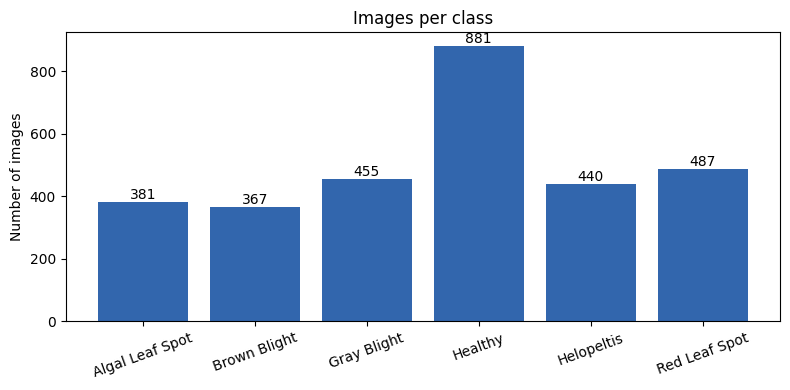

Example original sizes (W x H): [(640, 640)]


In [4]:
counts = {c: len(v) for c, v in class_to_files.items()}
total_images = sum(counts.values())
print("Total images:", total_images)

plt.figure(figsize=(8, 4))
bars = plt.bar(counts.keys(), counts.values(), color="#3266ad")
for b in bars:
    plt.text(b.get_x() + b.get_width()/2, b.get_height(), str(int(b.get_height())),
             ha="center", va="bottom", fontsize=10)
plt.title("Images per class")
plt.ylabel("Number of images")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/class_distribution.png", dpi=150)
plt.show()

# Original image sizes (check a few per class)
sizes = []
for v in class_to_files.values():
    for p in v[:5]:
        try:
            sizes.append(Image.open(p).size)
        except Exception as e:
            print("Unreadable file skipped:", p)
print("Example original sizes (W x H):", sorted(set(sizes))[:5])

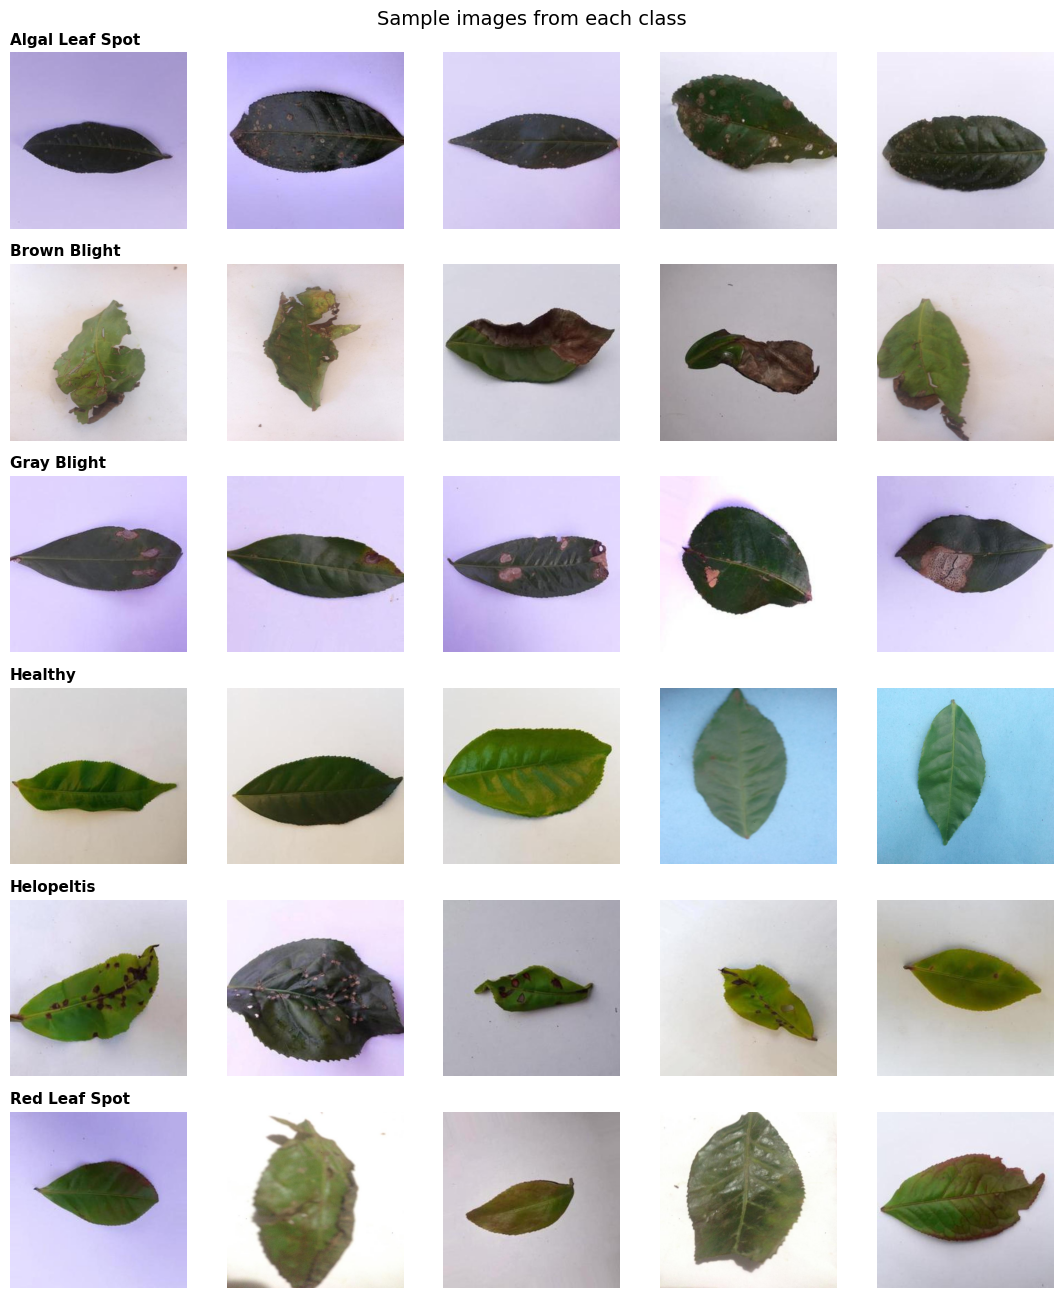

In [5]:
# A grid of sample images: 5 per class
n_per_class = 5
fig, axes = plt.subplots(NUM_CLASSES, n_per_class, figsize=(n_per_class*2.2, NUM_CLASSES*2.2))
for ax in axes.flat:
    ax.axis("off")
for i, c in enumerate(class_names):
    for j, p in enumerate(random.sample(class_to_files[c], min(n_per_class, len(class_to_files[c])))):
        axes[i, j].imshow(Image.open(p).convert("RGB"))
        axes[i, j].axis("off")
    axes[i, 0].set_title(c, loc="left", fontsize=11, fontweight="bold")
plt.suptitle("Sample images from each class", fontsize=14)
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/sample_images.png", dpi=150)
plt.show()

## 4. Train / validation / test split

- **Training set:** the model learns from these (its weights are updated on them).
- **Validation set:** checked after every epoch to watch for overfitting and to pick the best epoch. Never used to update weights.
- **Test set:** used **once, at the very end**, to report the final performance on completely unseen images.

**We use the dataset's own `train / valid / test` split** (after the cleaning in Section 2b), because the dataset authors created it so that each photo appears in only one split. If the provided validation or test set turns out too small (under 5% of the images each, or missing a class), the cell instead makes a fresh **stratified 70 / 15 / 15** split of the cleaned images, with one image per original photo, so no photo can leak across sets. The cell prints which option it used.

In [6]:
by_split = {s: [r for r in records if r["split"] == s] for s in ["train", "val", "test"]}
def has_all_classes(rs):
    return len({r["label"] for r in rs}) == NUM_CLASSES
use_provided = all(len(by_split[s]) >= 0.05 * total_images for s in ["val", "test"]) \
               and all(has_all_classes(by_split[s]) for s in ["train", "val", "test"])

if use_provided:
    SPLIT_MODE = "the dataset's own train/valid/test split"
    train_p = [r["path"] for r in by_split["train"]]; train_y = [r["label"] for r in by_split["train"]]
    val_p   = [r["path"] for r in by_split["val"]];   val_y   = [r["label"] for r in by_split["val"]]
    test_p  = [r["path"] for r in by_split["test"]];  test_y  = [r["label"] for r in by_split["test"]]
else:
    SPLIT_MODE = "a new stratified 70/15/15 split"
    all_paths  = [r["path"] for r in records]
    all_labels = [r["label"] for r in records]
    train_p, temp_p, train_y, temp_y = train_test_split(
        all_paths, all_labels, test_size=0.30, stratify=all_labels, random_state=SEED)
    val_p, test_p, val_y, test_y = train_test_split(
        temp_p, temp_y, test_size=0.50, stratify=temp_y, random_state=SEED)
print("Using", SPLIT_MODE)

def counts(y):
    return pd.Series(y).value_counts().reindex(range(NUM_CLASSES), fill_value=0).values
split_table = pd.DataFrame({"Train": counts(train_y), "Validation": counts(val_y), "Test": counts(test_y)},
                           index=class_names)
split_table.loc["Total"] = split_table.sum()
n_all = len(train_y) + len(val_y) + len(test_y)
print(split_table)
print(f"\nShares: train {len(train_y)/n_all:.0%}, validation {len(val_y)/n_all:.0%}, test {len(test_y)/n_all:.0%}")

Using the dataset's own train/valid/test split
                 Train  Validation  Test
Algal Leaf Spot    310          38    33
Brown Blight       300          35    32
Gray Blight        376          38    41
Healthy            545         164   172
Helopeltis         354          41    45
Red Leaf Spot      393          48    46
Total             2278         364   369

Shares: train 76%, validation 12%, test 12%


### Load the images into memory (once)

Decoding JPGs on every epoch is slow on Colab's 2 CPU cores, so we **resize every image to 128×128 once** and keep them in RAM (well under 1 GB; Colab's free tier has about 12 GB). Training then runs much faster. **Every image is converted to RGB** (3 channels), so greyscale or RGBA files can't break the model. Corrupt files, if any, are skipped.

In [7]:
IMG_SIZE   = 128
BATCH_SIZE = 32

def load_images(paths, labels):
    imgs, ys = [], []
    for p, y in zip(paths, labels):
        try:
            img = Image.open(p).convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
            imgs.append(img); ys.append(y)
        except Exception as e:
            print("Skipping unreadable file:", p, e)
    return imgs, ys

t0 = time.time()
train_imgs, train_y = load_images(train_p, train_y)
val_imgs,   val_y   = load_images(val_p,   val_y)
test_imgs,  test_y  = load_images(test_p,  test_y)
print(f"Loaded {len(train_imgs)} train / {len(val_imgs)} val / {len(test_imgs)} test images "
      f"in {time.time()-t0:.1f}s")

class LeafDataset(Dataset):
    # Holds pre-loaded PIL images + labels and applies a transform on the fly
    def __init__(self, images, labels, transform):
        self.images, self.labels, self.transform = images, labels, transform
    def __len__(self):
        return len(self.images)
    def __getitem__(self, idx):
        return self.transform(self.images[idx]), self.labels[idx]

Loaded 2278 train / 364 val / 369 test images in 13.9s


## 5. Round 1: basic transform only (no augmentation)

The minimal transform just turns each image into a tensor with values in `[0, 1]` and shape `[3, 128, 128]`. No flipping, rotating or colour changes yet.

Batch shape: (32, 3, 128, 128)


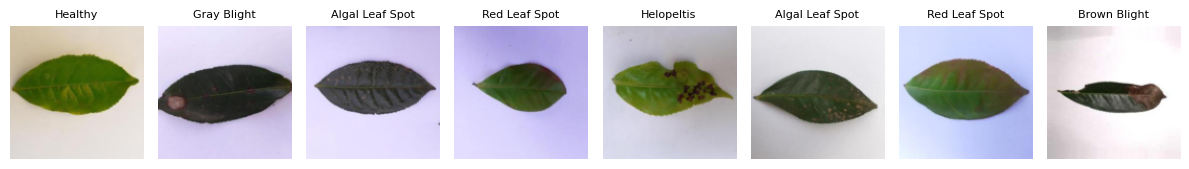

In [8]:
basic_transform = transforms.Compose([
    transforms.ToTensor(),             # PIL (already 128x128) -> tensor in [0, 1]
])

train_ds_plain = LeafDataset(train_imgs, train_y, basic_transform)
val_ds         = LeafDataset(val_imgs,   val_y,   basic_transform)
test_ds        = LeafDataset(test_imgs,  test_y,  basic_transform)

train_loader_plain = DataLoader(train_ds_plain, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader         = DataLoader(val_ds,         batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader        = DataLoader(test_ds,        batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

# One batch as a sanity check
images, labels = next(iter(train_loader_plain))
print("Batch shape:", tuple(images.shape))
plt.figure(figsize=(12, 3))
for i in range(8):
    plt.subplot(1, 8, i+1)
    plt.imshow(images[i].permute(1, 2, 0))
    plt.title(class_names[labels[i]], fontsize=8)
    plt.axis("off")
plt.tight_layout(); plt.show()

## 6. The CNN models

A CNN has two parts:

**A) Feature extractor (convolution + pooling).**
- A **filter (kernel)** is a small `3×3` grid of weights that slides over the image looking for one pattern: an edge, a colour blob, a dark spot. Its output is a **feature map** showing *where* that pattern appears.
- A **convolution layer** is a stack of many filters. Early layers find simple patterns (edges, colours); deeper layers combine them into complex ones (lesion shapes, leaf texture, insect marks).
- **ReLU** sets negative values to 0, which lets the network learn non-linear patterns.
- **MaxPool** halves the height and width, keeping the strongest signals. This makes the network faster and a little robust to small shifts.

**B) Classification head (fully-connected layers).** Flattens the feature maps into one vector, then `Linear` layers turn it into **5 scores**, one per class. The highest score is the prediction.

We build two versions:

| | `CNN_Basic` (Round 1) | `CNN_Improved` (Round 2) |
|---|---|---|
| Conv blocks | 3 (32 → 64 → 128 filters) | 4 (32 → 64 → 128 → 256 filters) |
| BatchNorm | ✗ | ✓ after every conv |
| Dropout | ✗ | ✓ 0.3 and 0.5 in the head |
| Training data | plain images | augmented images |

```
CNN_Basic, input 3×128×128
  Conv(32)  → ReLU → Pool  →  32×64×64
  Conv(64)  → ReLU → Pool  →  64×32×32
  Conv(128) → ReLU → Pool  → 128×16×16
  Flatten → Linear(256) → ReLU → Linear(5)
```

In [9]:
def conv_block(in_ch, out_ch, batchnorm=False):
    layers = [nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1)]
    if batchnorm:
        layers.append(nn.BatchNorm2d(out_ch))
    layers += [nn.ReLU(inplace=True), nn.MaxPool2d(2)]
    return nn.Sequential(*layers)

class CNN_Basic(nn.Module):
    # 3 conv blocks, no BatchNorm, no Dropout
    def __init__(self, num_classes=5, img_size=128):
        super().__init__()
        self.features = nn.Sequential(        # each block = Conv -> ReLU -> MaxPool
            conv_block(3, 32),
            conv_block(32, 64),
            conv_block(64, 128),
        )
        with torch.no_grad():
            n_flat = self.features(torch.zeros(1, 3, img_size, img_size)).numel()
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(n_flat, 256),
            nn.ReLU(inplace=True),
            nn.Linear(256, num_classes),
        )
    def forward(self, x):
        return self.classifier(self.features(x))

class CNN_Improved(nn.Module):
    # 4 conv blocks with BatchNorm + Dropout in the head
    def __init__(self, num_classes=5, img_size=128, p_dropout=0.5):
        super().__init__()
        self.features = nn.Sequential(        # each block = Conv -> BatchNorm -> ReLU -> MaxPool
            conv_block(3, 32, batchnorm=True),
            conv_block(32, 64, batchnorm=True),
            conv_block(64, 128, batchnorm=True),
            conv_block(128, 256, batchnorm=True),
        )
        with torch.no_grad():
            n_flat = self.features(torch.zeros(1, 3, img_size, img_size)).numel()
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(n_flat, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(p_dropout),
            nn.Linear(256, num_classes),
        )
    def forward(self, x):
        return self.classifier(self.features(x))

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

model_basic = CNN_Basic(NUM_CLASSES, IMG_SIZE).to(device)
print(model_basic)
print(f"\nTrainable parameters: {count_params(model_basic):,}")

CNN_Basic(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=32768, out_features=256, bias=True)
    (2): ReLU(inplace=True)
    (3): Linear(in_features=256, out_features=6, bias=True)
  )
)

Trainable parameters: 8,483,654


In [10]:
# Layer-by-layer summary (output shapes + parameters)
try:
    from torchsummary import summary
except ImportError:
    !pip install -q torchsummary
    from torchsummary import summary
summary(model_basic, input_size=(3, IMG_SIZE, IMG_SIZE), device=device.type)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 32, 128, 128]             896
              ReLU-2         [-1, 32, 128, 128]               0
         MaxPool2d-3           [-1, 32, 64, 64]               0
            Conv2d-4           [-1, 64, 64, 64]          18,496
              ReLU-5           [-1, 64, 64, 64]               0
         MaxPool2d-6           [-1, 64, 32, 32]               0
            Conv2d-7          [-1, 128, 32, 32]          73,856
              ReLU-8          [-1, 128, 32, 32]               0
         MaxPool2d-9          [-1, 128, 16, 16]               0
          Flatten-10                [-1, 32768]               0
           Linear-11                  [-1, 256]       8,388,864
             ReLU-12                  [-1, 256]               0
           Linear-13                    [-1, 6]           1,542
Total params: 8,483,654
Trainable param

## 7. Training loop

Each **epoch**:
1. **Train:** for each batch, forward pass → compute the **CrossEntropy loss** → backpropagate → the **Adam** optimizer updates the weights.
2. **Validate:** measure loss and accuracy on the validation set (no weight updates, `torch.no_grad()`).
3. Save the weights whenever validation accuracy reaches a new best, so we can use the **best epoch** (not just the last one) for testing.

- **Loss:** how wrong the model is (lower is better).
- **Accuracy:** fraction of images classified correctly (higher is better).

In [11]:
def run_epoch(model, loader, criterion, optimizer=None):
    # Trains if an optimizer is given, otherwise evaluates. Returns (loss, accuracy).
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for imgs, labels in loader:
            imgs, labels = imgs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * imgs.size(0)
            correct    += (outputs.argmax(1) == labels).sum().item()
            total      += labels.size(0)
    return total_loss / total, correct / total

def train_model(model, train_loader, val_loader, epochs=20, lr=1e-3, weight_decay=0.0,
                scheduler_type=None, save_path="best_model.pth"):
    # scheduler_type: None (constant LR) or "cosine" (LR decays smoothly from lr to lr/100)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = (torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=lr/100)
                 if scheduler_type == "cosine" else None)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "lr": []}
    best_val_acc, best_epoch = 0.0, 0
    start = time.time()

    for epoch in range(1, epochs + 1):
        lr_now = optimizer.param_groups[0]["lr"]
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)
        if scheduler:
            scheduler.step()

        for k, v in zip(history.keys(), [tr_loss, va_loss, tr_acc, va_acc, lr_now]):
            history[k].append(v)

        flag = ""
        if va_acc > best_val_acc:
            best_val_acc, best_epoch = va_acc, epoch
            torch.save(model.state_dict(), save_path)
            flag = "  ✓ best"
        print(f"Epoch {epoch:2d}/{epochs} | lr {lr_now:.1e} | "
              f"train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
              f"val loss {va_loss:.4f} acc {va_acc:.4f}{flag}")

    history["train_time_s"] = time.time() - start
    history["best_epoch"], history["best_val_acc"] = best_epoch, best_val_acc
    print(f"\nTraining time: {history['train_time_s']/60:.1f} min | "
          f"best val acc {best_val_acc:.4f} at epoch {best_epoch}")
    model.load_state_dict(torch.load(save_path, map_location=device))   # restore the best weights
    return history

In [12]:
# Plot helper for loss / accuracy curves
BLUE, ORANGE, GRAY = "#3266ad", "#e07b39", "#88877f"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.linestyle": "--", "grid.alpha": 0.5})

def plot_history(h, title, fname):
    ep = np.arange(1, len(h["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
    ax1.plot(ep, h["train_acc"], "o-", color=BLUE, ms=4, label="Train")
    ax1.plot(ep, h["val_acc"],   "o-", color=ORANGE, ms=4, label="Validation")
    ax1.axvline(h["best_epoch"], color=GRAY, ls=":", label=f"Best epoch ({h['best_epoch']})")
    ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x*100:.0f}%"))
    ax1.set_title("Accuracy (higher = better)"); ax1.set_xlabel("Epoch"); ax1.legend()

    ax2.plot(ep, h["train_loss"], "o-", color=BLUE, ms=4, label="Train")
    ax2.plot(ep, h["val_loss"],   "o-", color=ORANGE, ms=4, label="Validation")
    ax2.axvline(h["best_epoch"], color=GRAY, ls=":")
    ax2.set_title("Loss (lower = better)"); ax2.set_xlabel("Epoch"); ax2.legend()
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.savefig(f"{RESULTS_DIR}/{fname}", dpi=150, bbox_inches="tight")
    plt.show()

### Train Round 1 (basic CNN, no augmentation)
About 1 to 3 minutes on a T4 GPU.

Epoch  1/20 | lr 1.0e-03 | train loss 1.3565 acc 0.4135 | val loss 1.1692 acc 0.3956  ✓ best
Epoch  2/20 | lr 1.0e-03 | train loss 0.9952 acc 0.5838 | val loss 0.7885 acc 0.7033  ✓ best
Epoch  3/20 | lr 1.0e-03 | train loss 0.8817 acc 0.6466 | val loss 0.7076 acc 0.7088  ✓ best
Epoch  4/20 | lr 1.0e-03 | train loss 0.7684 acc 0.6949 | val loss 0.8332 acc 0.6593
Epoch  5/20 | lr 1.0e-03 | train loss 0.6784 acc 0.7331 | val loss 0.6086 acc 0.7500  ✓ best
Epoch  6/20 | lr 1.0e-03 | train loss 0.5680 acc 0.7757 | val loss 0.7544 acc 0.7418
Epoch  7/20 | lr 1.0e-03 | train loss 0.5026 acc 0.7976 | val loss 0.6977 acc 0.7363
Epoch  8/20 | lr 1.0e-03 | train loss 0.4330 acc 0.8363 | val loss 0.4568 acc 0.8379  ✓ best
Epoch  9/20 | lr 1.0e-03 | train loss 0.3291 acc 0.8758 | val loss 0.5674 acc 0.7940
Epoch 10/20 | lr 1.0e-03 | train loss 0.2471 acc 0.9065 | val loss 0.4766 acc 0.8352
Epoch 11/20 | lr 1.0e-03 | train loss 0.1750 acc 0.9342 | val loss 0.5646 acc 0.7967
Epoch 12/20 | lr 1.0e-03 

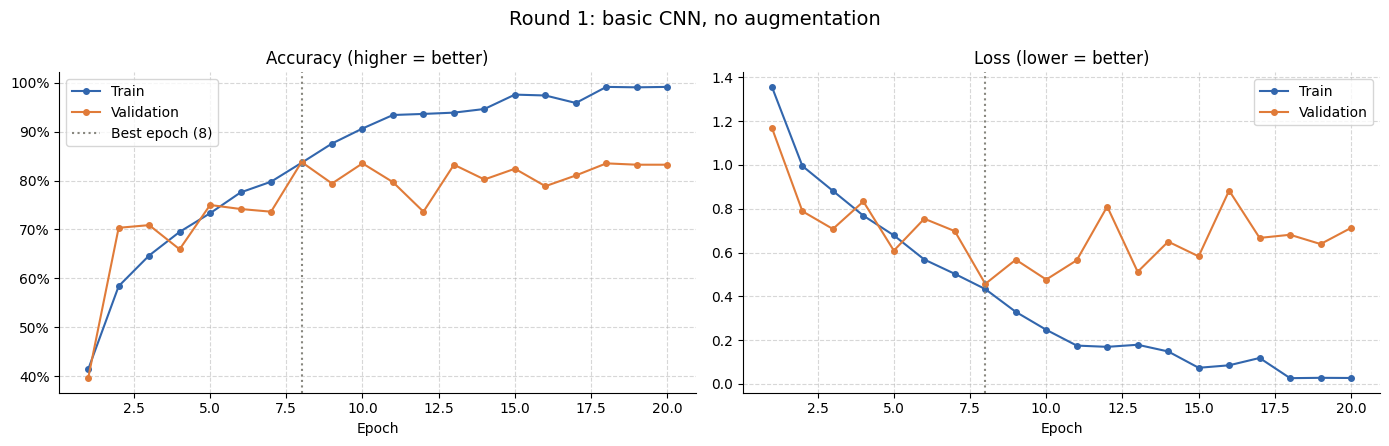

In [13]:
EPOCHS_R1 = 20
history_basic = train_model(model_basic, train_loader_plain, val_loader,
                            epochs=EPOCHS_R1, lr=1e-3,
                            save_path=f"{RESULTS_DIR}/cnn_basic_best.pth")
plot_history(history_basic, "Round 1: basic CNN, no augmentation", "curves_round1.png")

### Spot the overfitting 🔍

Signs of overfitting to look for:
- **Training accuracy** climbs toward 100% and **training loss** keeps falling toward 0.
- **Validation accuracy** levels off well below it, and **validation loss** stops falling and **rises again**.

**What this run shows: clear overfitting.** Up to epoch 8, training and validation improve together (both ≈84% accuracy, validation loss falls to its minimum of **0.457**). After that:
- training accuracy keeps climbing to **99.2%**, and training loss falls to **0.027**;
- validation accuracy stays stuck between **73.6% and 83.5%**;
- validation loss rises again, swinging up to **0.883** and ending at **0.713**.

The final gap is **15.9 percentage points**. With only 2,278 training images and 8.5 million parameters, the basic model memorizes the training images instead of learning general disease patterns. Keeping the weights from the best validation epoch (8) limits the damage, but this model is clearly too flexible for this much data. Round 2 addresses exactly this.

## 8. Visualize what the CNN learned 👀

1. **Filters of the first conv layer:** each is a `3×3×3` colour patch. They tend to become edge and colour detectors.
2. **Feature maps:** how each filter responds to a real leaf. Bright areas mean "this pattern is here".
3. **Feature maps of the last conv layer:** smaller and more abstract, encoding higher-level features.

Sample image class: Helopeltis


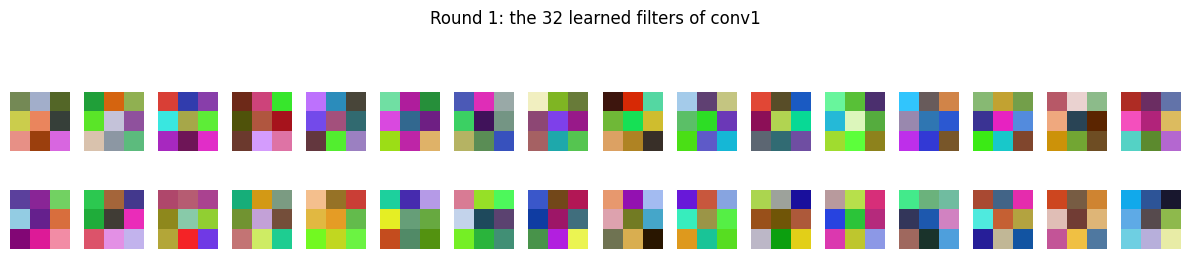

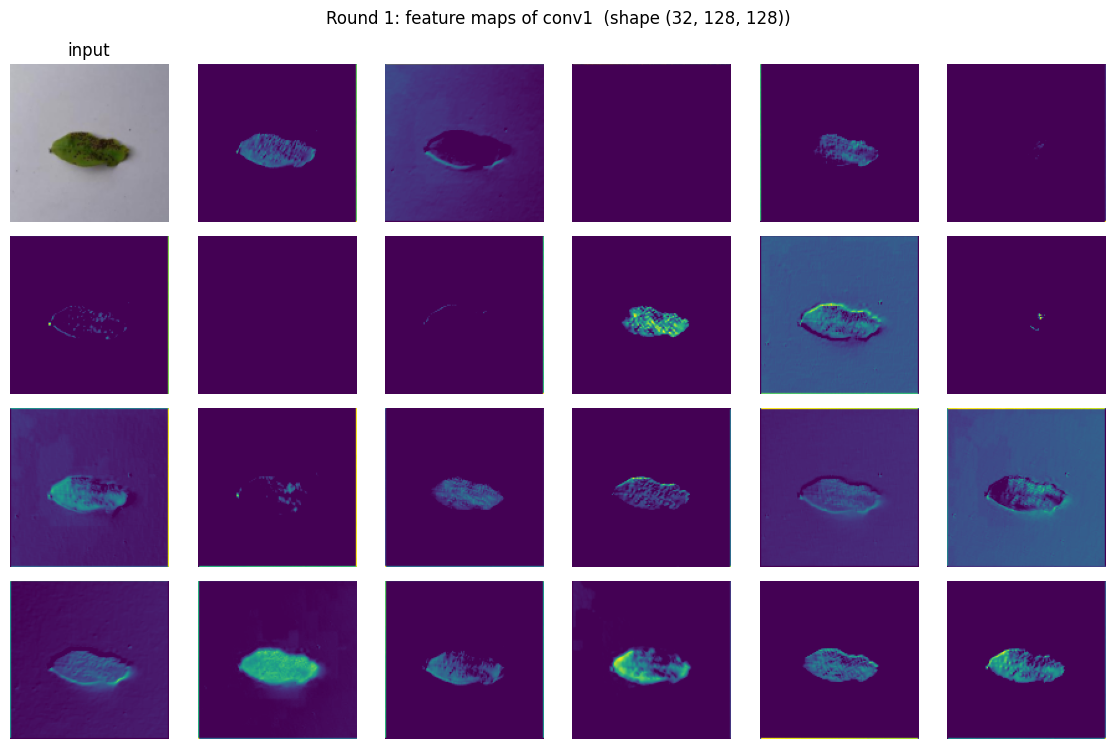

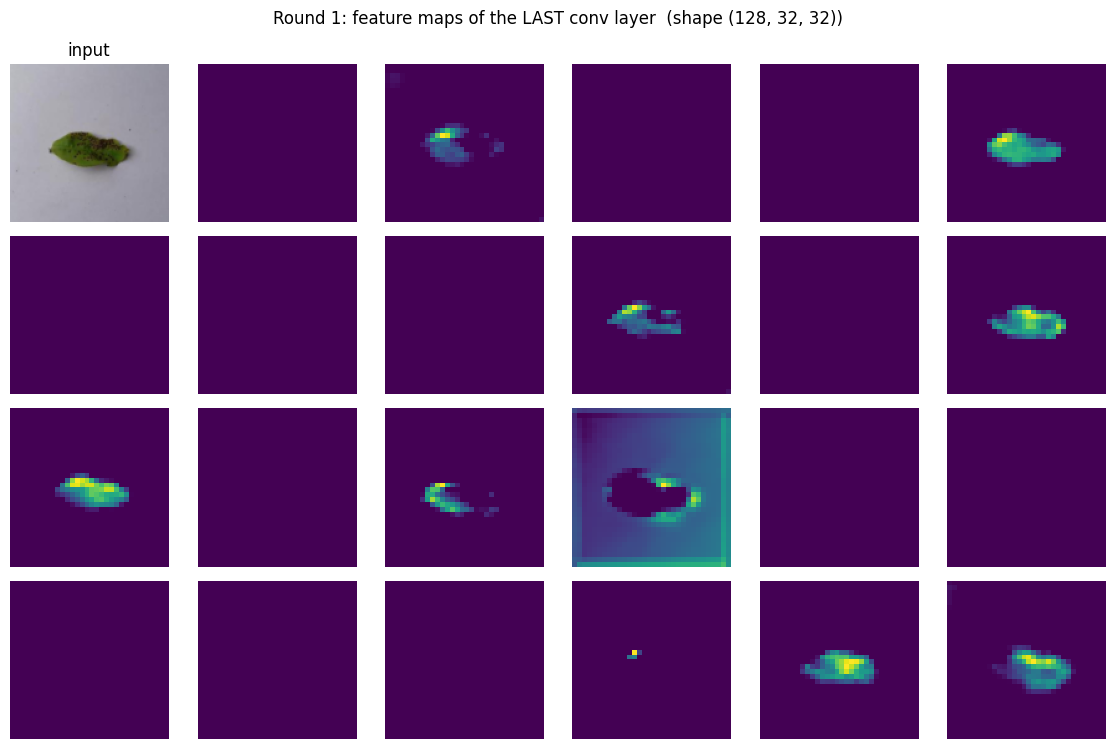

In [14]:
def show_filters(model, title, fname):
    w = model.features[0][0].weight.data.clone().cpu()          # [32, 3, 3, 3]
    w = (w - w.min()) / (w.max() - w.min() + 1e-8)
    n = w.shape[0]
    plt.figure(figsize=(12, 3))
    for i in range(n):
        plt.subplot(2, n // 2, i + 1)
        plt.imshow(w[i].permute(1, 2, 0)); plt.axis("off")
    plt.suptitle(title); plt.tight_layout()
    plt.savefig(f"{RESULTS_DIR}/{fname}", dpi=150); plt.show()

def show_feature_maps(model, img, title, fname, layer="first", n_maps=23):
    model.eval()
    x = img.unsqueeze(0).to(device)
    with torch.no_grad():
        if layer == "first":
            maps = F.relu(model.features[0][0](x))           # conv1 output, before pooling
        else:
            blocks = list(model.features)
            for b in blocks[:-1]:
                x = b(x)
            maps = blocks[-1][:-1](x)                        # last block, before pooling
    maps = maps.cpu()[0]
    cols = 6; rows = int(np.ceil((n_maps + 1) / cols))
    plt.figure(figsize=(cols*1.9, rows*1.9))
    plt.subplot(rows, cols, 1); plt.imshow(img.permute(1, 2, 0)); plt.title("input"); plt.axis("off")
    for i in range(min(n_maps, maps.shape[0])):
        plt.subplot(rows, cols, i + 2); plt.imshow(maps[i], cmap="viridis"); plt.axis("off")
    plt.suptitle(f"{title}  (shape {tuple(maps.shape)})"); plt.tight_layout()
    plt.savefig(f"{RESULTS_DIR}/{fname}", dpi=150); plt.show()

# pick one diseased validation leaf for the visualizations
sample_idx = next((i for i, y in enumerate(val_y) if "healthy" not in class_names[y].lower()), 0)
sample_img, sample_label = val_ds[sample_idx]
print("Sample image class:", class_names[sample_label])

show_filters(model_basic, "Round 1: the 32 learned filters of conv1", "filters_round1.png")
show_feature_maps(model_basic, sample_img, "Round 1: feature maps of conv1", "fmaps_first_round1.png", "first")
show_feature_maps(model_basic, sample_img, "Round 1: feature maps of the LAST conv layer", "fmaps_last_round1.png", "last")

## 9. Round 2: fix overfitting with augmentation, BatchNorm and dropout

1. **Data augmentation (training set only).** Every time a training image is used, it gets a random flip, rotation, crop/zoom and brightness/contrast change. Detached leaves are photographed at any angle, distance and light, so this teaches the model to handle that variety and stops it memorizing exact pictures. Validation and test images stay **unchanged**, so we measure performance on normal images. We deliberately use **no hue shift** and only a small saturation change: lesion colour (reddish, brown, grey) is one of the main differences between these diseases, so shifting it would teach the model wrong labels.
2. **BatchNorm** after every conv layer stabilizes and speeds up training.
3. **Dropout (0.5)** randomly switches off half of the neurons in the classification head during training, so the network can't rely on a few features.
4. **Weight decay** (L2), a lower starting learning rate (`5e-4`) and a **cosine learning-rate schedule** that lowers the learning rate smoothly to `5e-6` by the last epoch. A smaller, decaying step size keeps BatchNorm's running statistics stable, so validation results don't jump around between epochs.
5. **More epochs (50).** Augmented data is harder to fit, so the regularized model needs longer to converge than the basic one.

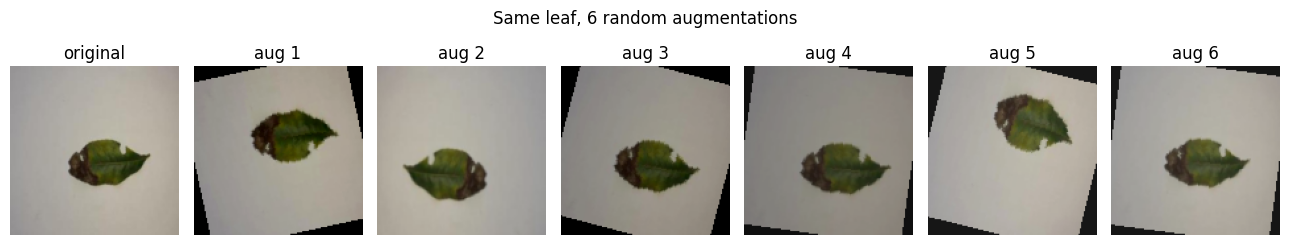

In [15]:
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),    # random zoom / crop
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),                             # a detached leaf has no fixed "up"
    transforms.RandomRotation(20),
    # Only mild colour changes and NO hue shift: lesion colour (red, brown, grey) separates several diseases
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
    transforms.ToTensor(),
])

train_ds_aug     = LeafDataset(train_imgs, train_y, train_transform)
train_loader_aug = DataLoader(train_ds_aug, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)

# The SAME image, augmented 6 different ways
plt.figure(figsize=(13, 2.6))
plt.subplot(1, 7, 1); plt.imshow(train_imgs[0]); plt.title("original"); plt.axis("off")
for i in range(6):
    plt.subplot(1, 7, i + 2); plt.imshow(train_ds_aug[0][0].permute(1, 2, 0)); plt.title(f"aug {i+1}"); plt.axis("off")
plt.suptitle("Same leaf, 6 random augmentations"); plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/augmentation_examples.png", dpi=150); plt.show()

In [16]:
model_improved = CNN_Improved(NUM_CLASSES, IMG_SIZE, p_dropout=0.5).to(device)
print(f"Trainable parameters: {count_params(model_improved):,}")
summary(model_improved, input_size=(3, IMG_SIZE, IMG_SIZE), device=device.type)

Trainable parameters: 4,585,478
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 32, 128, 128]             896
       BatchNorm2d-2         [-1, 32, 128, 128]              64
              ReLU-3         [-1, 32, 128, 128]               0
         MaxPool2d-4           [-1, 32, 64, 64]               0
            Conv2d-5           [-1, 64, 64, 64]          18,496
       BatchNorm2d-6           [-1, 64, 64, 64]             128
              ReLU-7           [-1, 64, 64, 64]               0
         MaxPool2d-8           [-1, 64, 32, 32]               0
            Conv2d-9          [-1, 128, 32, 32]          73,856
      BatchNorm2d-10          [-1, 128, 32, 32]             256
             ReLU-11          [-1, 128, 32, 32]               0
        MaxPool2d-12          [-1, 128, 16, 16]               0
           Conv2d-13          [-1, 256, 16, 16]         295,168
      B

### Train Round 2
50 epochs, about 5 to 10 minutes on a T4 GPU, depending on how many images were kept.

Epoch  1/50 | lr 5.0e-04 | train loss 1.4990 acc 0.4421 | val loss 1.1758 acc 0.4945  ✓ best
Epoch  2/50 | lr 5.0e-04 | train loss 1.0814 acc 0.5623 | val loss 0.9263 acc 0.6209  ✓ best
Epoch  3/50 | lr 5.0e-04 | train loss 1.0289 acc 0.5904 | val loss 0.6553 acc 0.7555  ✓ best
Epoch  4/50 | lr 5.0e-04 | train loss 0.9310 acc 0.6339 | val loss 0.6034 acc 0.7857  ✓ best
Epoch  5/50 | lr 4.9e-04 | train loss 0.8684 acc 0.6532 | val loss 0.6895 acc 0.7225
Epoch  6/50 | lr 4.9e-04 | train loss 0.8829 acc 0.6422 | val loss 0.6293 acc 0.7610
Epoch  7/50 | lr 4.8e-04 | train loss 0.8301 acc 0.6738 | val loss 1.1903 acc 0.5192
Epoch  8/50 | lr 4.8e-04 | train loss 0.7800 acc 0.6936 | val loss 0.7302 acc 0.6593
Epoch  9/50 | lr 4.7e-04 | train loss 0.7661 acc 0.6980 | val loss 0.4631 acc 0.8324  ✓ best
Epoch 10/50 | lr 4.6e-04 | train loss 0.7252 acc 0.7309 | val loss 0.4767 acc 0.8049
Epoch 11/50 | lr 4.5e-04 | train loss 0.7215 acc 0.7309 | val loss 0.4517 acc 0.8407  ✓ best
Epoch 12/50 | lr 

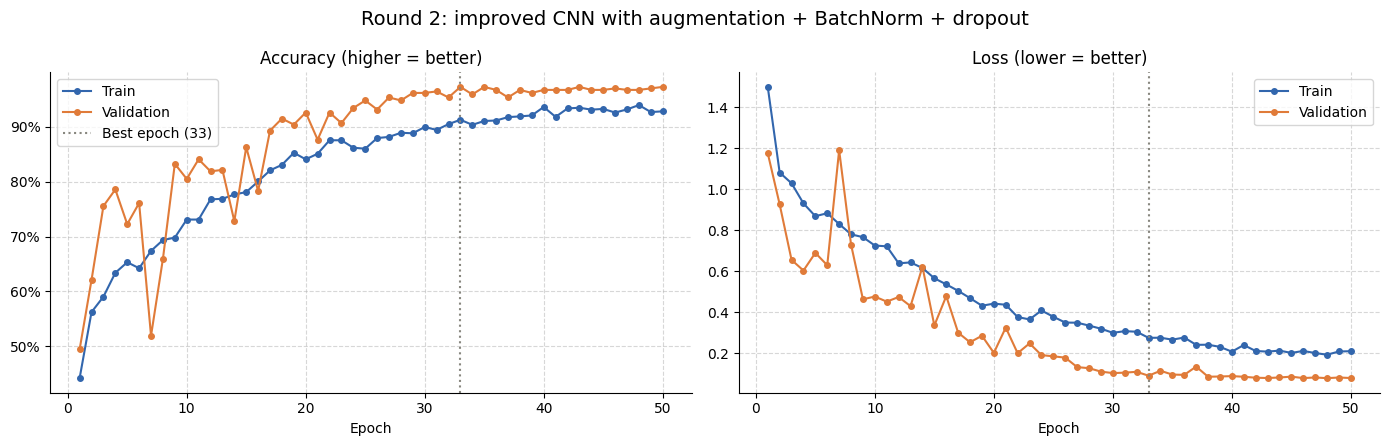

In [17]:
EPOCHS_R2 = 50
history_improved = train_model(model_improved, train_loader_aug, val_loader,
                               epochs=EPOCHS_R2, lr=5e-4, weight_decay=1e-4, scheduler_type="cosine",
                               save_path=f"{RESULTS_DIR}/cnn_improved_best.pth")
plot_history(history_improved, "Round 2: improved CNN with augmentation + BatchNorm + dropout",
             "curves_round2.png")

**How to read the Round 2 curves: neither overfit nor underfit.**

- **Not overfit:** validation loss keeps falling to the end (**0.079** at epoch 50) and never rises again. Validation accuracy stays high and stable: **95.3% to 97.3% from epoch 29 on**, varying by only ±0.2 points over the last 10 epochs.
- **Not underfit:** both curves reach high accuracy: **97.25%** best validation, and ≈93% training on *augmented* images. Training loss falls steadily from 1.50 to about 0.21.
- **Why validation accuracy is above training accuracy** (97.3% vs 92.8% at the last epoch): training accuracy is measured on randomly flipped, rotated, cropped and colour-jittered images with dropout switched on. Those are harder than the clean validation images, so a small negative gap is normal with augmentation and dropout.
- **The early dips** at epochs **7 (51.9%)**, **14 (72.8%)**, **16 (78.3%)** and **21 (87.6%)** happen while training loss keeps falling smoothly. They are a known side effect of **BatchNorm**: at evaluation time it uses running averages of the batch statistics, which lag behind the weights while the learning rate is high, and which come from augmented batches while validation images are clean. As the cosine schedule lowers the learning rate, the dips stop. From epoch 22 on, validation accuracy stays above 90%. We keep the weights from the **best validation epoch (33)**, so these early epochs don't affect the final model.

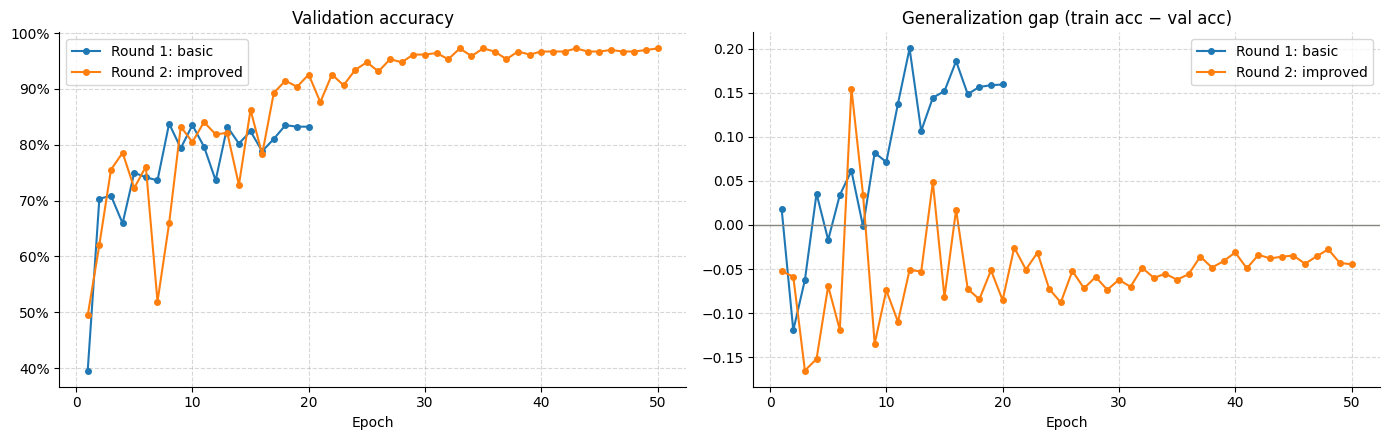

Best val acc Round 1: 0.8379  (epoch 8)
Best val acc Round 2: 0.9725  (epoch 33)
Final-epoch gap Round 1: 0.1592 | Round 2: -0.0445


In [18]:
# Compare the two rounds side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
ax1.plot(np.arange(1, len(history_basic["val_acc"])+1), history_basic["val_acc"], "o-", ms=4, label="Round 1: basic")
ax1.plot(np.arange(1, len(history_improved["val_acc"])+1), history_improved["val_acc"], "o-", ms=4, label="Round 2: improved")
ax1.set_title("Validation accuracy"); ax1.set_xlabel("Epoch"); ax1.legend()
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x*100:.0f}%"))

gap1 = np.array(history_basic["train_acc"]) - np.array(history_basic["val_acc"])
gap2 = np.array(history_improved["train_acc"]) - np.array(history_improved["val_acc"])
ax2.plot(np.arange(1, len(gap1)+1), gap1, "o-", ms=4, label="Round 1: basic")
ax2.plot(np.arange(1, len(gap2)+1), gap2, "o-", ms=4, label="Round 2: improved")
ax2.axhline(0, color=GRAY, lw=1)
ax2.set_title("Generalization gap (train acc − val acc)"); ax2.set_xlabel("Epoch"); ax2.legend()
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/round_comparison.png", dpi=150); plt.show()

print(f"Best val acc Round 1: {history_basic['best_val_acc']:.4f}  (epoch {history_basic['best_epoch']})")
print(f"Best val acc Round 2: {history_improved['best_val_acc']:.4f}  (epoch {history_improved['best_epoch']})")
print(f"Final-epoch gap Round 1: {gap1[-1]:.4f} | Round 2: {gap2[-1]:.4f}")

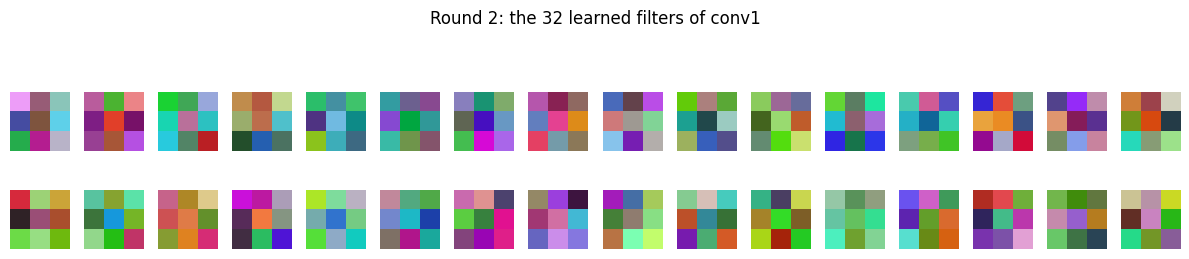

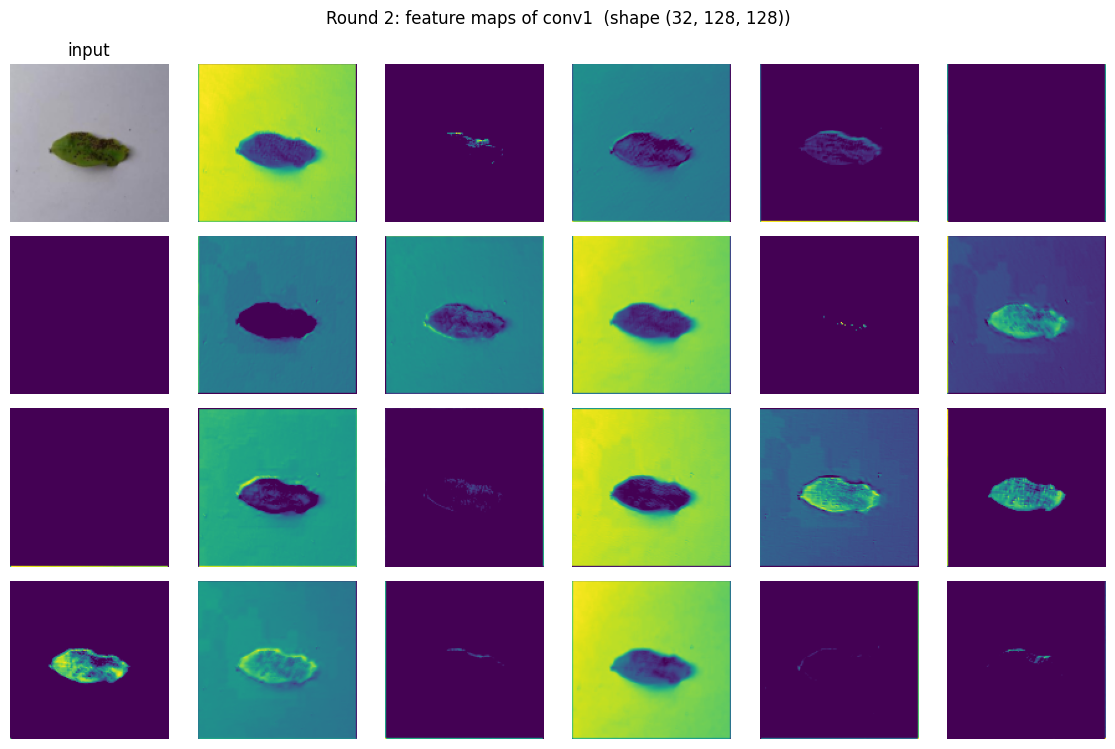

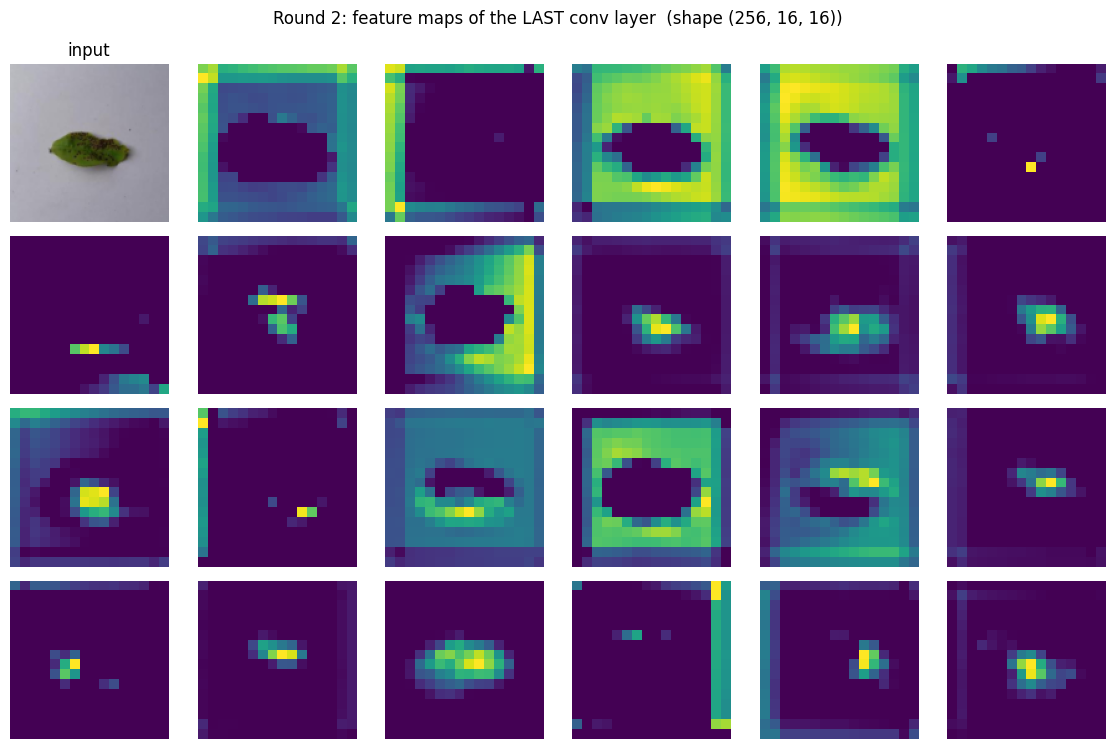

In [19]:
show_filters(model_improved, "Round 2: the 32 learned filters of conv1", "filters_round2.png")
show_feature_maps(model_improved, sample_img, "Round 2: feature maps of conv1", "fmaps_first_round2.png", "first")
show_feature_maps(model_improved, sample_img, "Round 2: feature maps of the LAST conv layer", "fmaps_last_round2.png", "last")

## 10. Final evaluation on the test set

The test set was never used for training or for choosing the best epoch, so this is the honest measure of how well each model works on new leaves. Both models are evaluated with their best saved weights.

In [20]:
def get_predictions(model, loader):
    model.eval()
    probs, targets = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            probs.append(F.softmax(model(imgs.to(device)), dim=1).cpu())
            targets.append(labels)
    probs = torch.cat(probs).numpy()
    return probs.argmax(1), torch.cat(targets).numpy(), probs

def summarize(name, model, history, y_true, y_pred):
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"Model": name,
            "Parameters": f"{count_params(model):,}",
            "Best epoch": history["best_epoch"],
            "Train time (min)": round(history["train_time_s"]/60, 2),
            "Best val acc": round(history["best_val_acc"], 4),
            "Test accuracy": round(accuracy_score(y_true, y_pred), 4),
            "Macro precision": round(p, 4),
            "Macro recall": round(r, 4),
            "Macro F1": round(f1, 4)}

pred_b, true_b, prob_b = get_predictions(model_basic, test_loader)
pred_i, true_i, prob_i = get_predictions(model_improved, test_loader)

results = pd.DataFrame([summarize("Round 1: CNN_Basic", model_basic, history_basic, true_b, pred_b),
                        summarize("Round 2: CNN_Improved", model_improved, history_improved, true_i, pred_i)])
results.to_csv(f"{RESULTS_DIR}/results_comparison.csv", index=False)
results

,Model,Parameters,Best epoch,Train time (min),Best val acc,Test accuracy,Macro precision,Macro recall,Macro F1
0,Round 1: CNN_Basic,"8,483,654",8,0.70,0.8379,0.8266,0.8039,0.7867,0.7892
1,Round 2: CNN_Improved,"4,585,478",33,4.54,0.9725,0.9702,0.9549,0.9601,0.9570


From here on we analyze the **final model (Round 2)** in detail: `y_true`, `y_pred` and `y_prob` hold its test-set results. To analyze the Round 1 model instead, change the next cell to use `pred_b, true_b, prob_b` and `model_basic`.

In [21]:
final_model = model_improved
y_pred, y_true, y_prob = pred_i, true_i, prob_i
print(f"Final test accuracy: {accuracy_score(y_true, y_pred)*100:.2f}%  "
      f"({(y_pred == y_true).sum()}/{len(y_true)} test images correct)")

Final test accuracy: 97.02%  (358/369 test images correct)


### Confusion matrix

Row = true class, column = predicted class. The diagonal holds the correct predictions; off-diagonal cells show which diseases get confused with each other. The right-hand plot shows the same matrix as row percentages (per-class recall).

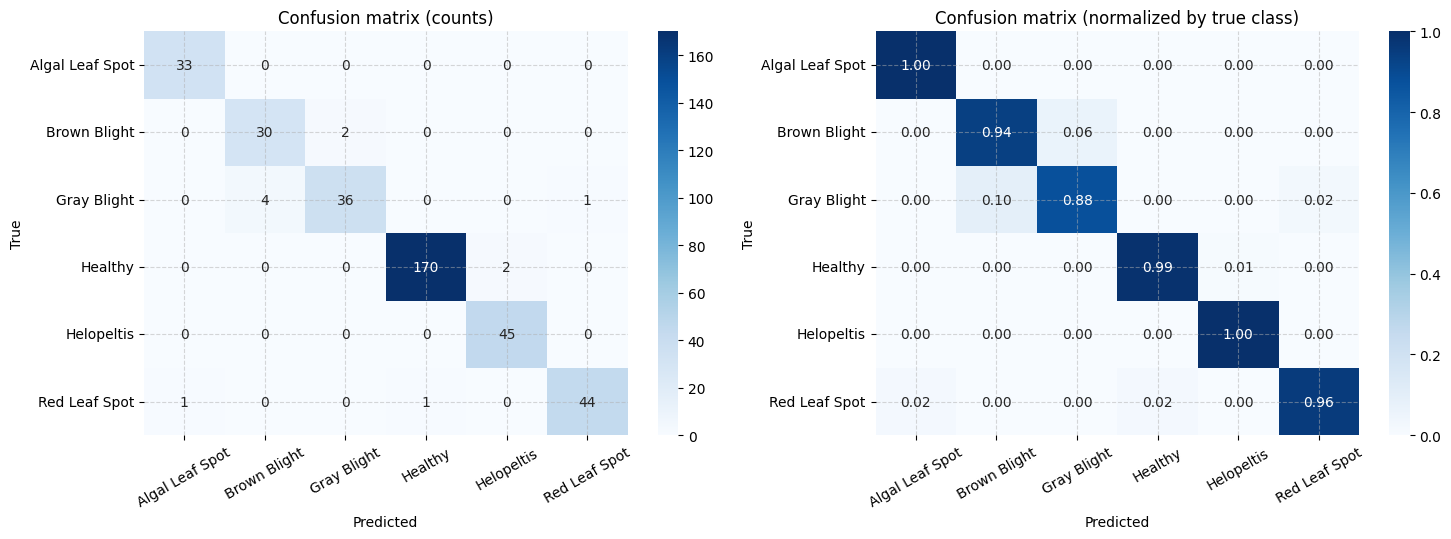

In [22]:
cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
cm_norm = cm.astype(float) / np.maximum(cm.sum(axis=1, keepdims=True), 1)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title("Confusion matrix (counts)"); axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("True")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=class_names, yticklabels=class_names,
            ax=axes[1], vmin=0, vmax=1)
axes[1].set_title("Confusion matrix (normalized by true class)"); axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("True")
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/confusion_matrix.png", dpi=150); plt.show()

### Classification report (precision, recall, F1)

- **Precision:** of all leaves *predicted* as class X, how many really were X (few false alarms).
- **Recall:** of all leaves that *really are* class X, how many the model found (few misses).
- **F1-score:** the balance (harmonic mean) of precision and recall.
- **Support:** number of test images in that class.

In [23]:
report = classification_report(y_true, y_pred, labels=list(range(NUM_CLASSES)), target_names=class_names, zero_division=0, digits=4)
print(report)
pd.DataFrame(classification_report(y_true, y_pred, labels=list(range(NUM_CLASSES)), target_names=class_names, zero_division=0, output_dict=True)
             ).transpose().to_csv(f"{RESULTS_DIR}/classification_report.csv")

                 precision    recall  f1-score   support

Algal Leaf Spot     0.9706    1.0000    0.9851        33
   Brown Blight     0.8824    0.9375    0.9091        32
    Gray Blight     0.9474    0.8780    0.9114        41
        Healthy     0.9942    0.9884    0.9913       172
     Helopeltis     0.9574    1.0000    0.9783        45
  Red Leaf Spot     0.9778    0.9565    0.9670        46

       accuracy                         0.9702       369
      macro avg     0.9549    0.9601    0.9570       369
   weighted avg     0.9706    0.9702    0.9701       369



### Per-class accuracy, best and worst classes

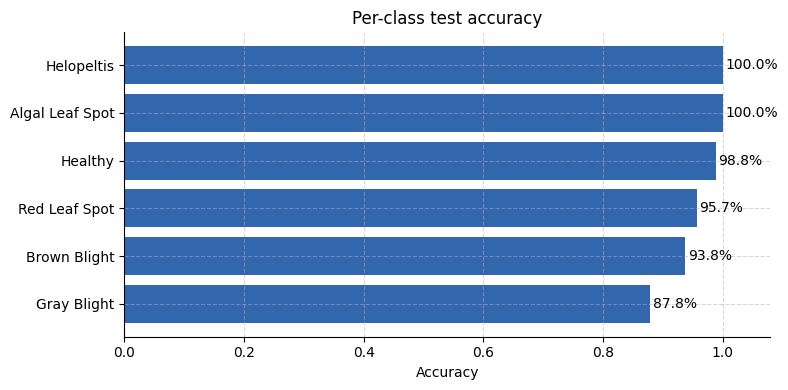

Best class : Helopeltis (100.00%)
Worst class: Gray Blight (87.80%)

Most common mistakes (true → predicted):
  Gray Blight → Brown Blight: 4 images
  Healthy → Helopeltis: 2 images
  Brown Blight → Gray Blight: 2 images
  Red Leaf Spot → Healthy: 1 images
  Red Leaf Spot → Algal Leaf Spot: 1 images


In [24]:
per_class_acc = cm.diagonal() / np.maximum(cm.sum(axis=1), 1)
order = np.argsort(per_class_acc)

plt.figure(figsize=(8, 4))
bars = plt.barh([class_names[i] for i in order], per_class_acc[order], color=BLUE)
for b, v in zip(bars, per_class_acc[order]):
    plt.text(v + 0.005, b.get_y() + b.get_height()/2, f"{v*100:.1f}%", va="center")
plt.xlim(0, 1.08); plt.xlabel("Accuracy"); plt.title("Per-class test accuracy")
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/per_class_accuracy.png", dpi=150); plt.show()

print(f"Best class : {class_names[order[-1]]} ({per_class_acc[order[-1]]*100:.2f}%)")
print(f"Worst class: {class_names[order[0]]} ({per_class_acc[order[0]]*100:.2f}%)")

# Most frequent confusions
off = [(cm[i, j], class_names[i], class_names[j]) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j and cm[i, j] > 0]
print("\nMost common mistakes (true → predicted):")
for n, t, p in sorted(off, reverse=True)[:5]:
    print(f"  {t} → {p}: {n} images")

### ROC curves (one-vs-rest)

For each class, the ROC curve shows the trade-off between catching that disease (true positive rate) and false alarms (false positive rate) as the decision threshold changes. **AUC** = 1.0 is perfect; 0.5 is random guessing.

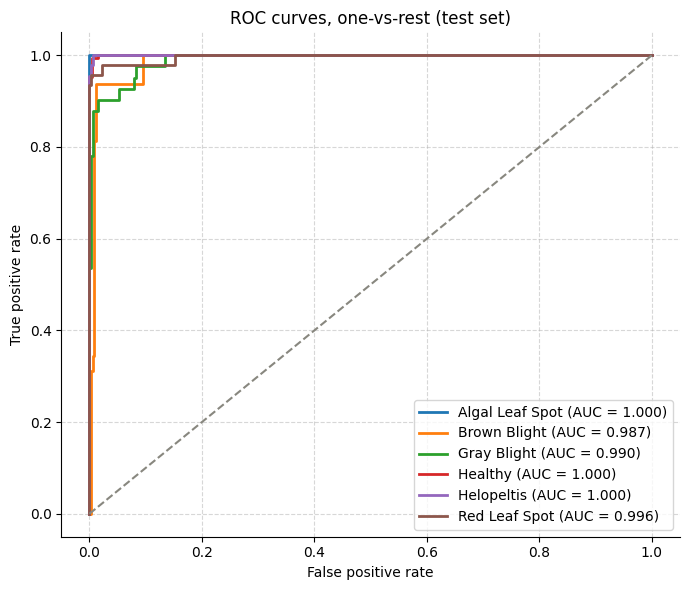

In [25]:
y_true_bin = label_binarize(y_true, classes=list(range(NUM_CLASSES)))
plt.figure(figsize=(7, 6))
for i, c in enumerate(class_names):
    if y_true_bin[:, i].sum() == 0:        # class absent from the test set
        continue
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_prob[:, i])
    plt.plot(fpr, tpr, lw=2, label=f"{c} (AUC = {auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "--", color=GRAY)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves, one-vs-rest (test set)"); plt.legend(loc="lower right")
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/roc_curves.png", dpi=150); plt.show()

### Sample predictions

Random test images with the predicted class and the model's confidence. Green title = correct, red = wrong.

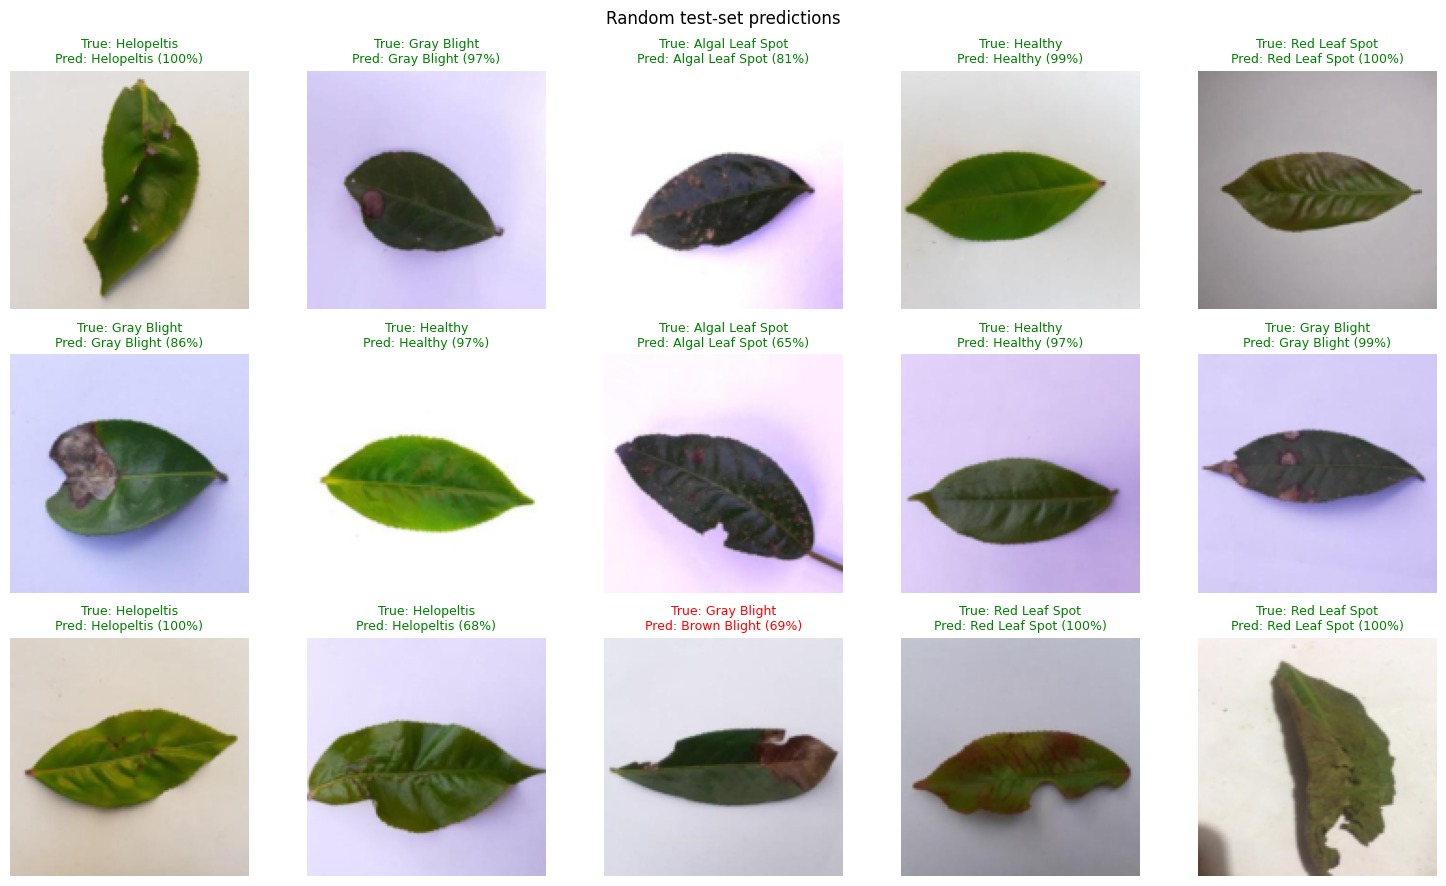

In [26]:
idxs = random.sample(range(len(test_ds)), 15)
plt.figure(figsize=(15, 9))
for k, idx in enumerate(idxs):
    img, label = test_ds[idx]
    pred, conf = y_pred[idx], y_prob[idx].max()
    plt.subplot(3, 5, k + 1)
    plt.imshow(img.permute(1, 2, 0))
    plt.title(f"True: {class_names[label]}\nPred: {class_names[pred]} ({conf*100:.0f}%)",
              fontsize=9, color="green" if pred == label else "red")
    plt.axis("off")
plt.suptitle("Random test-set predictions"); plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/sample_predictions.png", dpi=150); plt.show()

### Misclassified images

Looking at the mistakes shows *why* the model fails: similar-looking lesions, early-stage symptoms, blur, shadows or busy backgrounds.

Total misclassified test images: 11 / 369


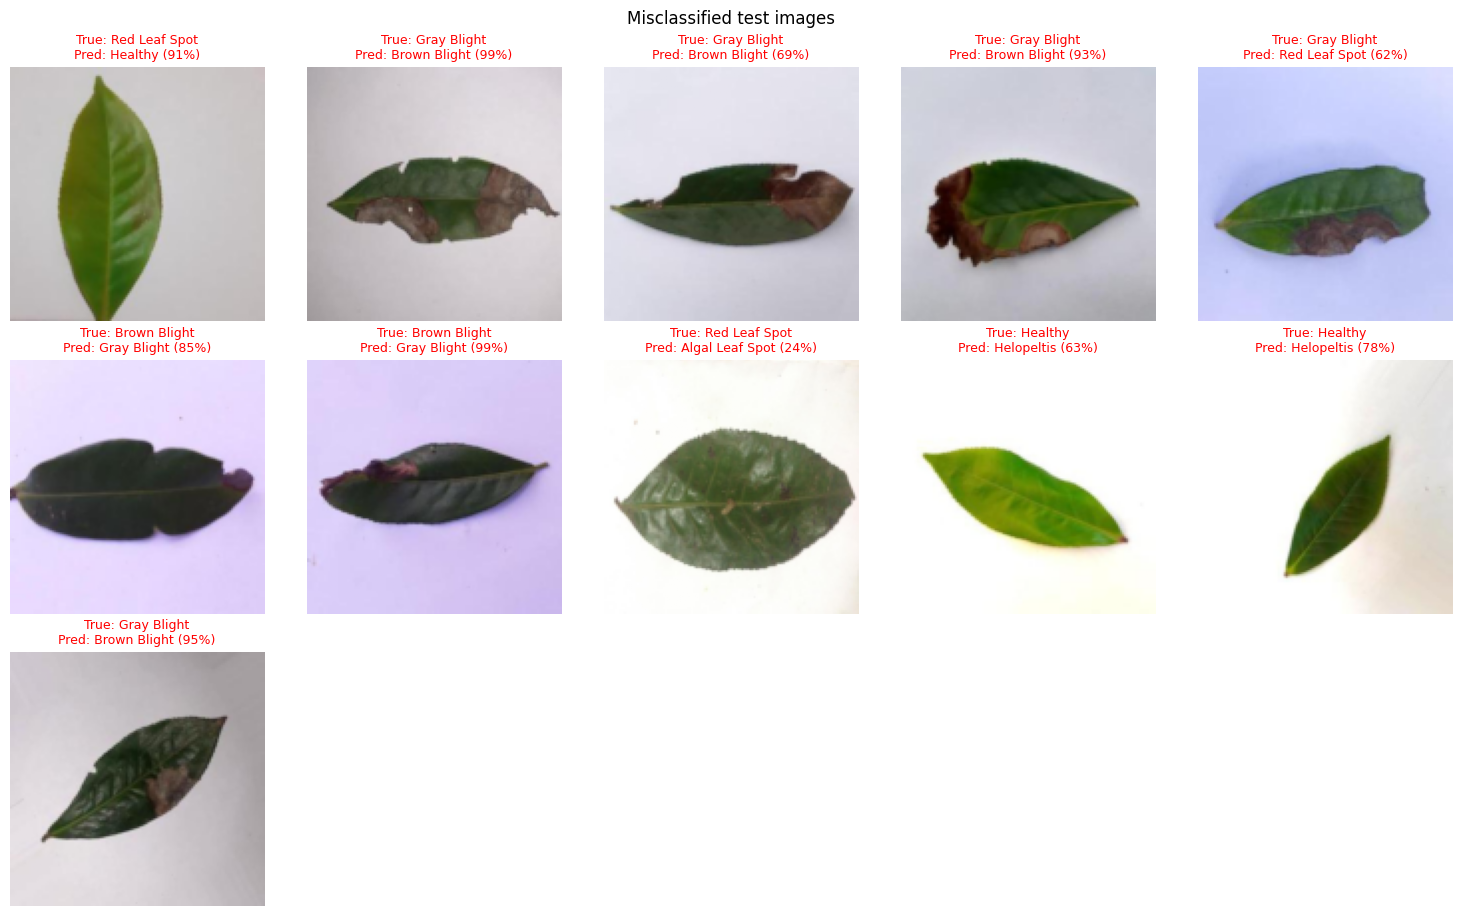

In [27]:
wrong = np.where(y_pred != y_true)[0]
print(f"Total misclassified test images: {len(wrong)} / {len(y_true)}")

n_show = min(20, len(wrong))
if n_show:
    cols = 5; rows = int(np.ceil(n_show / cols))
    plt.figure(figsize=(cols*3, rows*3.1))
    for k, idx in enumerate(wrong[:n_show]):
        img, label = test_ds[idx]
        plt.subplot(rows, cols, k + 1)
        plt.imshow(img.permute(1, 2, 0))
        plt.title(f"True: {class_names[label]}\nPred: {class_names[y_pred[idx]]} ({y_prob[idx].max()*100:.0f}%)",
                  fontsize=9, color="red")
        plt.axis("off")
    plt.suptitle("Misclassified test images"); plt.tight_layout()
    plt.savefig(f"{RESULTS_DIR}/misclassified.png", dpi=150); plt.show()

## 11. Results summary (generated from your run)

This cell writes a short summary using **your actual numbers**. Use it as the starting point for your report's discussion.

In [28]:
rb, ri = results.iloc[0], results.iloc[1]
g1 = history_basic["train_acc"][-1] - history_basic["val_acc"][-1]
g2 = history_improved["train_acc"][-1] - history_improved["val_acc"][-1]
worst_pair = sorted(off, reverse=True)[0] if off else None

summary_text = f'''
RESULTS SUMMARY: Tea leaf disease classification ({NUM_CLASSES} classes, {total_images} images after cleaning)
Split: {len(train_imgs)} train / {len(val_imgs)} validation / {len(test_imgs)} test ({SPLIT_MODE})

Round 1, CNN_Basic (3 conv blocks, no augmentation/BN/dropout):
  test accuracy {rb['Test accuracy']*100:.2f}%, macro F1 {rb['Macro F1']:.4f};
  final train-val accuracy gap {g1*100:.1f} percentage points.
Round 2, CNN_Improved (4 conv blocks + BatchNorm + dropout + augmentation):
  test accuracy {ri['Test accuracy']*100:.2f}%, macro F1 {ri['Macro F1']:.4f};
  final train-val accuracy gap {g2*100:.1f} percentage points.
Change in test accuracy: {(ri['Test accuracy']-rb['Test accuracy'])*100:+.2f} percentage points.

Final model per-class accuracy: best = {class_names[order[-1]]} ({per_class_acc[order[-1]]*100:.1f}%),
worst = {class_names[order[0]]} ({per_class_acc[order[0]]*100:.1f}%).
'''
if worst_pair:
    summary_text += f"Most frequent confusion: {worst_pair[1]} predicted as {worst_pair[2]} ({worst_pair[0]} images).\n"
print(summary_text)
with open(f"{RESULTS_DIR}/results_summary.txt", "w") as f:
    f.write(summary_text + "\n\n" + report)


RESULTS SUMMARY: Tea leaf disease classification (6 classes, 3011 images after cleaning)
Split: 2278 train / 364 validation / 369 test (the dataset's own train/valid/test split)

Round 1, CNN_Basic (3 conv blocks, no augmentation/BN/dropout):
  test accuracy 82.66%, macro F1 0.7892;
  final train-val accuracy gap 15.9 percentage points.
Round 2, CNN_Improved (4 conv blocks + BatchNorm + dropout + augmentation):
  test accuracy 97.02%, macro F1 0.9570;
  final train-val accuracy gap -4.5 percentage points.
Change in test accuracy: +14.36 percentage points.

Final model per-class accuracy: best = Helopeltis (100.0%),
worst = Gray Blight (87.8%).
Most frequent confusion: Gray Blight predicted as Brown Blight (4 images).



## 12. Discussion and conclusion

### 1. Overfitting in Round 1
The basic CNN has **8,483,654 parameters** (99% of them in its first fully-connected layer) and is trained on **2,278 images** with no augmentation, BatchNorm or dropout. It overfits clearly:
- Training accuracy climbs to **99.2%** and training loss falls to **0.027**.
- Validation accuracy stops improving at about epoch 8 (best **83.79%**) and then hovers around **82%** (average of the last 5 epochs).
- Validation loss is lowest at epoch 8 (**0.457**) and then rises, with large swings, to **0.712** by the last epoch.

The final train-validation gap is **15.9 percentage points**. The model memorizes the training images instead of learning general disease patterns.

### 2. Effect of augmentation, BatchNorm and dropout (Round 2)
| | Round 1 (basic) | Round 2 (improved) |
|---|---|---|
| Parameters | 8,483,654 | **4,585,478** (−46%) |
| Best validation accuracy | 83.79% (epoch 8) | **97.25%** (epoch 33) |
| Final train − validation gap | +15.9 points | −4.5 points |
| Validation accuracy variation, last 10 epochs | ±2.9 points | **±0.2 points** |
| **Test accuracy** | 82.66% | **97.02%** (358 / 369) |
| **Macro F1** | 0.7892 | **0.9570** |
| Training time | 0.7 min | 4.5 min |

Round 2 improves test accuracy by **14.36 percentage points** and macro F1 by **0.168**, with 46% fewer parameters. On a dataset of this size, the regularization clearly pays off.

**Reading the Round 2 curves:**
- **Validation accuracy above training accuracy** (≈97% vs ≈93% at the end) is expected. Training accuracy is measured on augmented images with dropout switched on, which are harder than the clean validation images. It does **not** mean the model underfits: training loss falls steadily the whole time.
- **The dips at epochs 7, 14 and 16** come from BatchNorm while the learning rate is still high: its running statistics lag behind the changing weights. As the cosine schedule lowers the learning rate, they disappear. In the last 10 epochs validation accuracy varies by only ±0.2 points. The saved model comes from the best epoch (33), so the dips don't affect it.

### 3. Test-set performance of the final model
- **Test accuracy 97.02%** (358 / 369), macro precision 0.9549, macro recall 0.9601, **macro F1 0.9570**.
- **Perfect recall:** Algal Leaf Spot (33/33) and Helopeltis (45/45). **Healthy** 98.8% (170/172) and **Red Leaf Spot** 95.7% (44/46).
- **Weakest classes: the two blights.** Gray Blight has 87.8% recall (36/41) and Brown Blight 93.8% (30/32). Brown Blight also has the lowest precision (0.882), because 4 Gray Blight leaves were predicted as Brown Blight.
- **The 11 errors:**
  - Gray Blight → Brown Blight (4)
  - Brown Blight → Gray Blight (2)
  - Healthy → Helopeltis (2)
  - Gray Blight → Red Leaf Spot (1)
  - Red Leaf Spot → Healthy (1)
  - Red Leaf Spot → Algal Leaf Spot (1)
- **6 of the 11 blight errors are between the two blights.**

### 4. Why these errors happen (from the misclassified images)
- **Gray Blight ↔ Brown Blight (6 errors):** every misclassified blight leaf shows a large brown, dead patch at the leaf edge or tip. Gray blight lesions start brown and only turn grey, with dark rings, later. At this stage the two diseases look almost the same, and at 128×128 pixels the fine ring pattern is lost. Most of these errors were made with high confidence (85–99%).
- **Healthy → Helopeltis (2 errors):** both leaves are light, yellow-green healthy leaves. Many Helopeltis leaves in the dataset are also yellow-green (see the sample grid), so the model partly relies on leaf colour, not only on the dark feeding marks.
- **Red Leaf Spot → Healthy (1 error, 91%):** the leaf shows only a faint reddish tinge, with no clear spots, so it looks healthy.
- **Red Leaf Spot → Algal Leaf Spot (1 error):** a dark leaf with a few small spots. The model was very unsure (only 24% confidence for its top class).
- **Confidence:** 6 of the 11 wrong predictions were made with ≥80% confidence (mostly blight-vs-blight), and 1 with ≤50%.

### 5. Limitations
- **From detection to classification.** The dataset was annotated with bounding boxes for object detection. We converted it to one label per image (the class covering most of the box area). Of the **5,180** images, we removed **1,990** Roboflow augmented copies (keeping one image per original photo), **79** images without any box, and **100** photos that appeared in more than one of the dataset's own splits. That last group would have leaked test photos into training. **3,011 images** remain. No image had a second disease covering a large share of its boxes (0 mixed images).
- **Class imbalance.** Healthy is the largest class (881 images, 29%). In the provided test split it makes up **47% of the test images** (172 / 369), so overall accuracy leans toward the easy Healthy class. **Macro F1 (0.957)** is the fairer summary.
- **Background shortcut risk.** Several classes were photographed mostly on one background colour: many Algal Leaf Spot and Gray Blight leaves on lavender paper, some Healthy leaves on light blue. The model may partly use the background. Grad-CAM would show whether it does.
- Photos show detached leaves; leaves on the bush, in the field, will likely be harder.
- Images are downscaled to 128×128, which removes fine lesion detail. This hurts mainly the blight-vs-blight decision.
- One split with 369 test images, so each error changes accuracy by 0.27 points, and the smaller classes have only 32–46 test images each.

### 6. Future work
- Train at a higher resolution (224×224) to keep lesion detail.
- Train on the **cropped bounding boxes**, which the annotations make possible; this would also reduce the background shortcut.
- Use a class-weighted loss for the smaller classes.
- Use background-randomizing augmentation.
- Use transfer learning (ResNet, EfficientNet, MobileNet), Grad-CAM, and k-fold cross-validation.

### 7. Conclusion
A CNN trained from scratch classifies the six tea leaf classes with **97.02% test accuracy and 0.957 macro F1**. Without regularization the network overfits heavily: a 15.9-point gap and 82.66% test accuracy. Data augmentation on the training images only, BatchNorm, dropout, weight decay and a cosine learning-rate schedule remove that gap and add **14.4 points** of test accuracy with 46% fewer parameters. The remaining errors come mostly from **Gray Blight and Brown Blight**, whose brown, dead patches look alike at their early stage.

## 13. Save and download the results

All figures (`.png`), tables (`.csv`), the text summary and both trained models (`.pth`) are in `/content/results`. This cell zips them, downloads the zip and, if Google Drive is mounted, also copies it to `My Drive/tea_cnn_results.zip`.

In [30]:
shutil.make_archive("/content/tea_cnn_results", "zip", RESULTS_DIR)
print("Saved files:", sorted(os.listdir(RESULTS_DIR)))
if os.path.exists("/content/drive/MyDrive"):
    shutil.copy("/content/tea_cnn_results.zip", "/content/drive/MyDrive/tea_cnn_results.zip")
    print("Copied to Google Drive: My Drive/tea_cnn_results.zip")
try:
    from google.colab import files
    files.download("/content/tea_cnn_results.zip")
except Exception:
    pass

Saved files: ['augmentation_examples.png', 'class_distribution.png', 'classification_report.csv', 'cnn_basic_best.pth', 'cnn_improved_best.pth', 'confusion_matrix.png', 'curves_round1.png', 'curves_round2.png', 'discussion.md', 'filters_round1.png', 'filters_round2.png', 'fmaps_first_round1.png', 'fmaps_first_round2.png', 'fmaps_last_round1.png', 'fmaps_last_round2.png', 'misclassified.png', 'per_class_accuracy.png', 'results_comparison.csv', 'results_summary.txt', 'roc_curves.png', 'round_comparison.png', 'sample_images.png', 'sample_predictions.png']
Copied to Google Drive: My Drive/tea_cnn_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>